In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

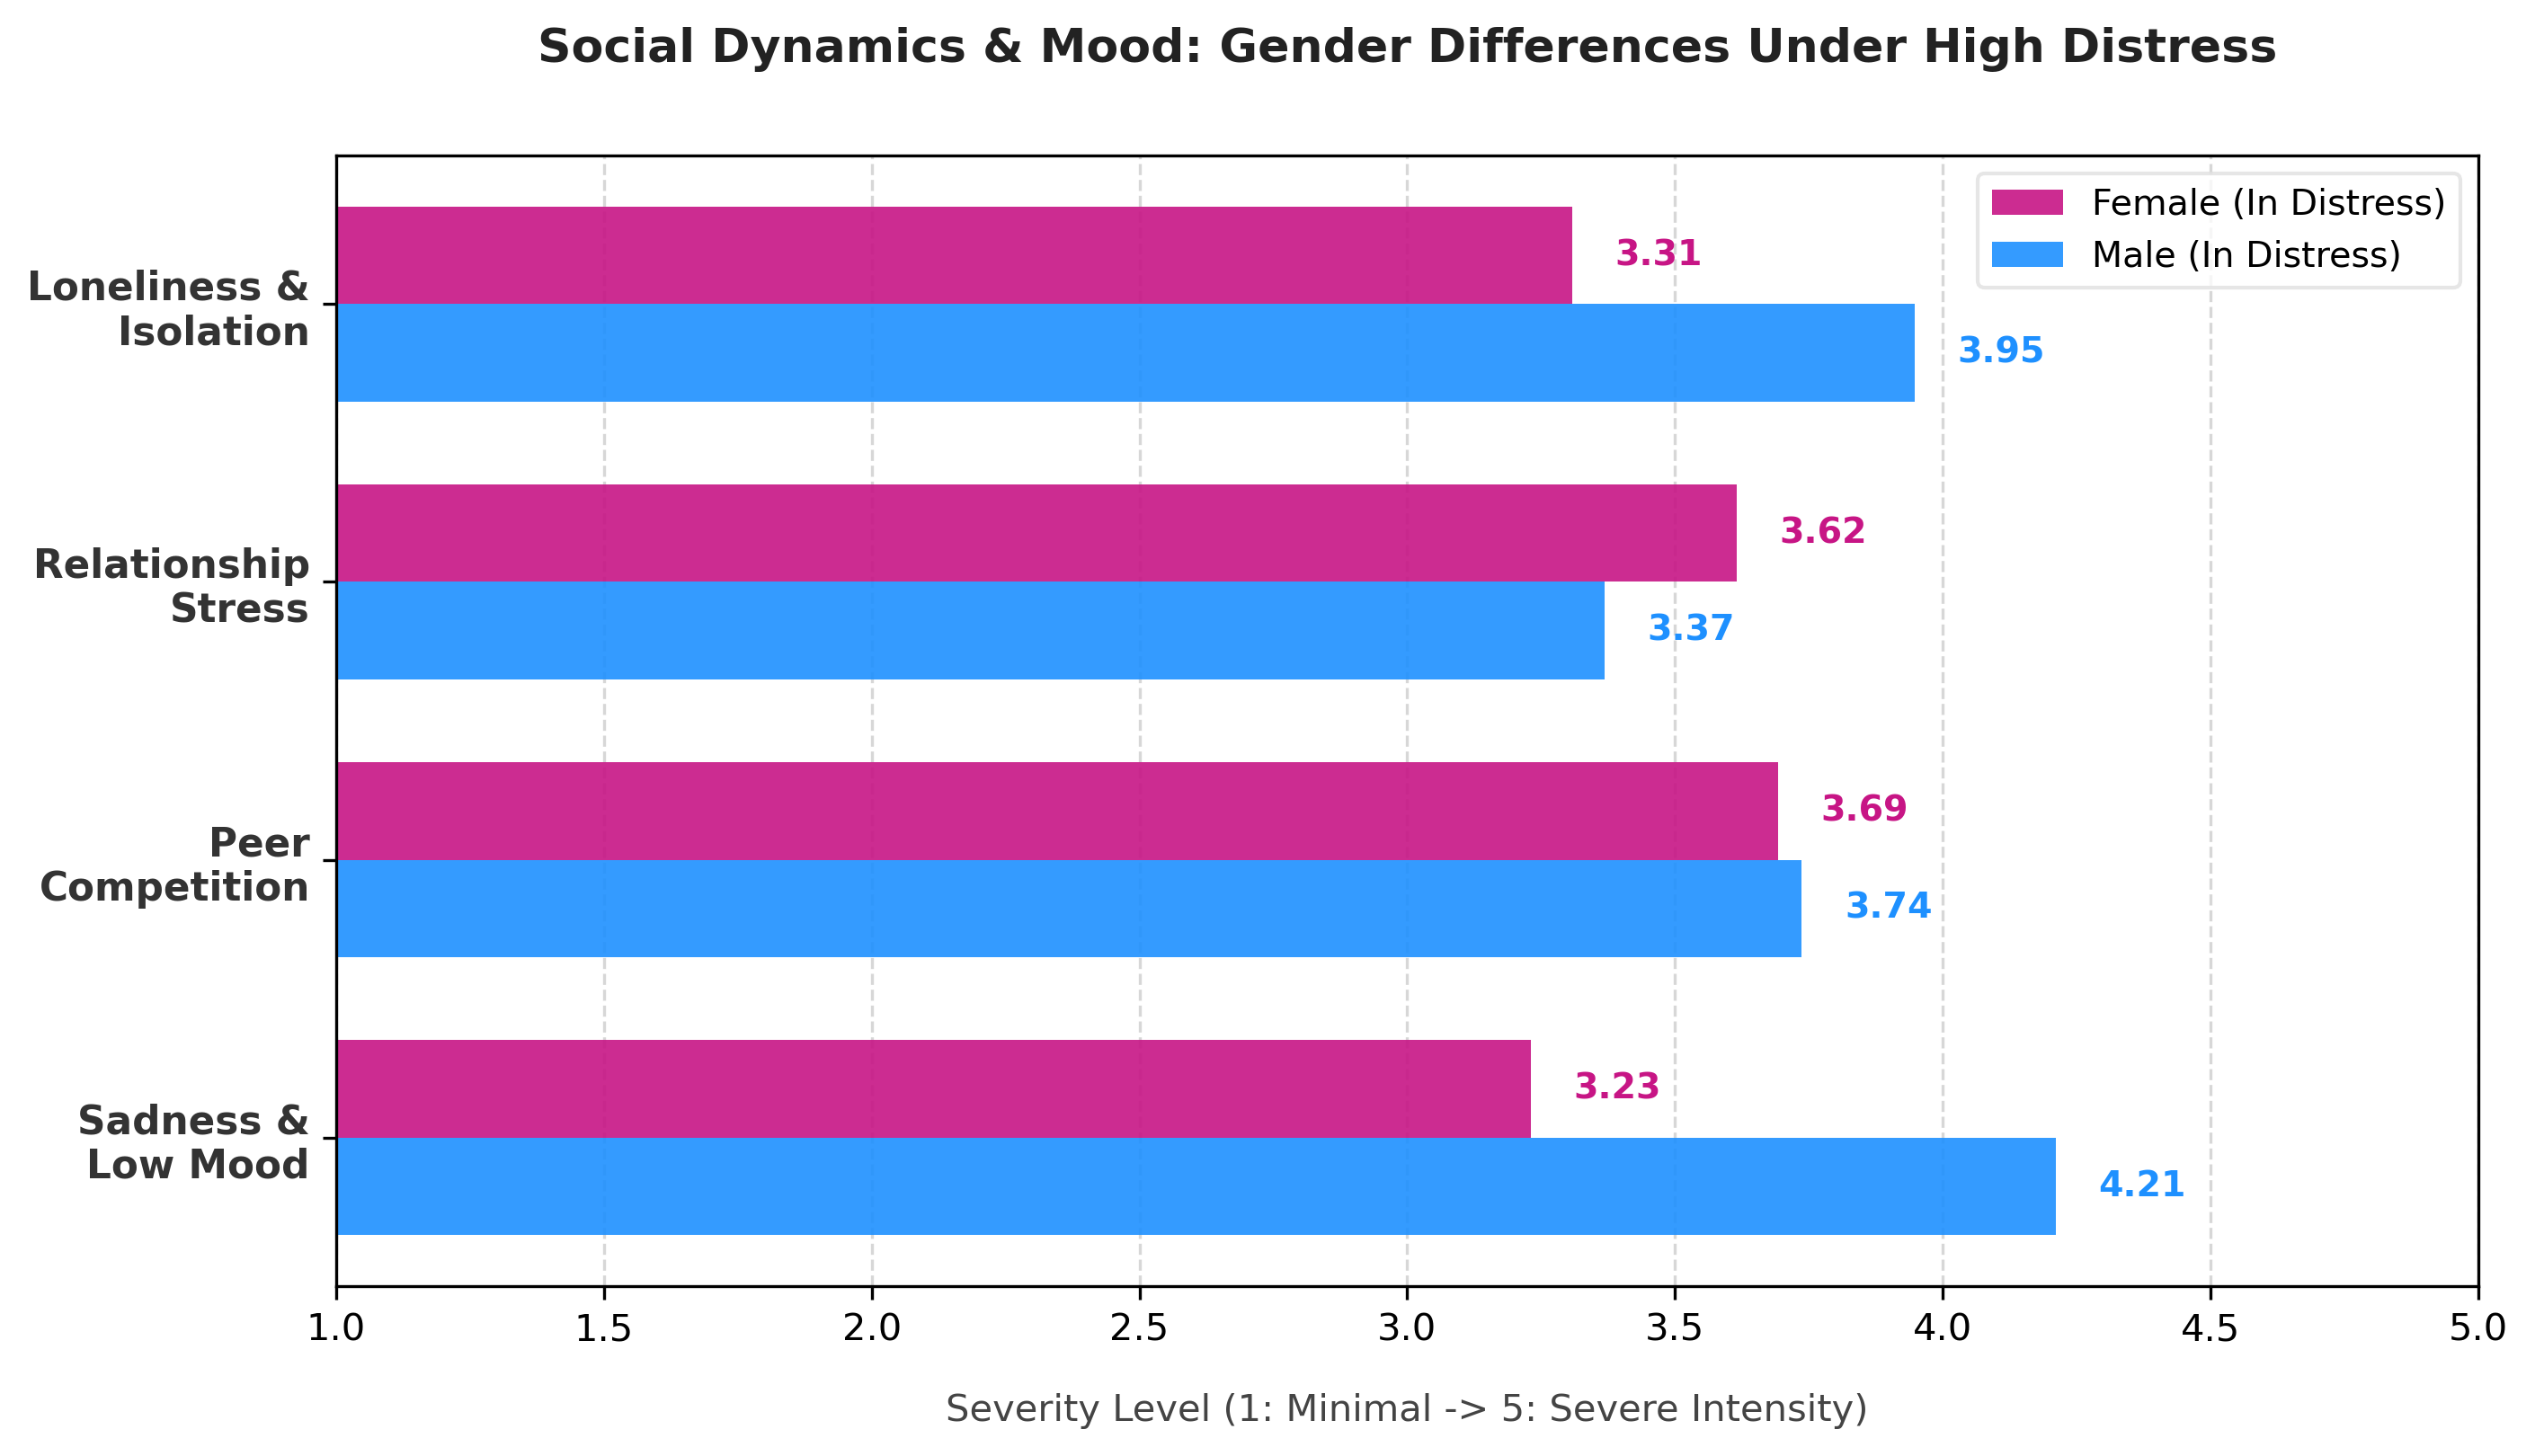

In [12]:
df = pd.read_csv('Stress_Dataset.csv')

df['Gender_Label'] = df['Gender'].map({0: 'Male', 1: 'Female'})

social_factors = [
    'Do you often feel lonely or isolated?',
    'Do you find that your relationship often causes you stress?',
    'Are you in competition with your peers, and does it affect you?',
    'Have you been feeling sadness or low mood?'
]

social_labels = [
    'Loneliness &\nIsolation',
    'Relationship\nStress',
    'Peer\nCompetition',
    'Sadness &\nLow Mood'
]

grouped = df.groupby(['Gender_Label', 'Which type of stress do you primarily experience?'])[social_factors].mean()

df_social = df.copy()

df_social['Stress_Type'] = df_social[
    'Which type of stress do you primarily experience?'
].map({
    'Eustress (Positive Stress) - Stress that motivates and enhances performance.': 'Eustress',
    'Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.': 'Distress'
})

df_social = df_social.dropna(subset=['Stress_Type'])

res = df_social.groupby(['Gender_Label', 'Stress_Type'])[social_factors].mean().reset_index()

fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=300)

bar_height = 0.35
y_positions = np.arange(len(social_labels))

female_distress = res[(res['Gender_Label']=='Female') & (res['Stress_Type']=='Distress')][social_factors].values.flatten()
male_distress = res[(res['Gender_Label']=='Male') & (res['Stress_Type']=='Distress')][social_factors].values.flatten()

f_color = '#C71585'
m_color = '#1E90FF' 

bars1 = ax.barh(y_positions - bar_height/2, female_distress, height=bar_height, color=f_color, label='Female (In Distress)', alpha=0.9)
bars2 = ax.barh(y_positions + bar_height/2, male_distress, height=bar_height, color=m_color, label='Male (In Distress)', alpha=0.9)

for bar in bars1:
    w = bar.get_width()
    ax.text(w + 0.08, bar.get_y() + bar.get_height()/2, f"{w:.2f}", ha='left', va='center', fontsize=9.5, fontweight='bold', color=f_color)

for bar in bars2:
    w = bar.get_width()
    ax.text(w + 0.08, bar.get_y() + bar.get_height()/2, f"{w:.2f}", ha='left', va='center', fontsize=9.5, fontweight='bold', color=m_color)

ax.set_yticks(y_positions)
ax.set_yticklabels(social_labels, fontsize=10.5, fontweight='bold', color='#333333')
ax.invert_yaxis()
ax.set_xlim(1.0, 5.0)
ax.set_xlabel('Severity Level (1: Minimal -> 5: Severe Intensity)', fontsize=10, labelpad=12, color='#444444')

ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(False)
ax.set_axisbelow(True)

ax.set_title('Social Dynamics & Mood: Gender Differences Under High Distress', fontsize=12.5, fontweight='bold', pad=25, color='#222222')
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='#E0E0E0', fontsize=9.5)

plt.tight_layout()
plt.show()